# 04 — Synthesis: was it the volcano or the weather?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ORG/etna-noise-practical/blob/main/notebooks/04_synthesis.ipynb)

**~10 minutes, mostly arguing.**

You now have three independent time series from the same three months:

1. **tremor amplitude** (0.5–5 Hz) — how hard the volcano is shaking
2. **secondary microseism amplitude** (0.1–0.35 Hz) — how hard the sea is
   shaking
3. **dv/v** — how much the seismic velocity of the medium has changed

And you have a chronology with two kinds of event in it. Put everything on
one time axis and decide what you believe.

In [1]:
# --- run me first ---------------------------------------------------
# Works both in the conda environment and in Google Colab.
import sys, os, importlib.util
if importlib.util.find_spec("obspy") is None:          # Colab
    !pip install -q obspy==1.5.1
#if not os.path.exists("etnalib"):                      # Colab
#    !git clone -q https://github.com/ORG/etna-noise-practical.git
#    %cd etna-noise-practical
#    !python scripts/get_data.py
sys.path.insert(0, os.path.abspath("."))
sys.path.insert(0, os.path.abspath(".."))

import numpy as np, matplotlib.pyplot as plt
from etnalib import config as C, io, plots
plots.style()
print("ready -- stations:", ", ".join(C.STATIONS))
# If a later cell says "No module named ...", it is almost always this line
# pointing somewhere other than the etna-noise environment: the notebook is
# running on a different kernel. Kernel > Change kernel, or see SETUP.md.
print("python:", sys.executable)

ready -- stations: ECPN, ESLN, EMSG, EFIU
python: /home/raphael/anaconda3/envs/etna-noise/bin/python


In [2]:
from etnalib import dvv

STA = "ECPN"
B = np.load(C.PROC / "band_series.npz")
Z = np.load(C.PROC / "daily_acf.npz", allow_pickle=True)

def series(sta, band):
    tk, vk = f"{sta}_{band}_t", f"{sta}_{band}_v"
    if tk not in B: return None, None
    return B[tk].astype("datetime64[s]"), B[vk]

acfs, days, lags = Z[f"{STA}_acf"], Z[f"{STA}_days"], Z["lags"]
out, ref, sel = dvv.dvv_series(acfs, list(days), lags, (3.0, 15.0),
                               ref_days=None)   # grand mean -- see nb 03
dd = np.array([np.datetime64(s[0]) for s in out])
vv = np.array([s[1] for s in out])
cc = np.array([s[2] for s in out])
print(f"{len(dd)} days of dv/v, median cc {np.nanmedian(cc):.3f}")

62 days of dv/v, median cc 0.778


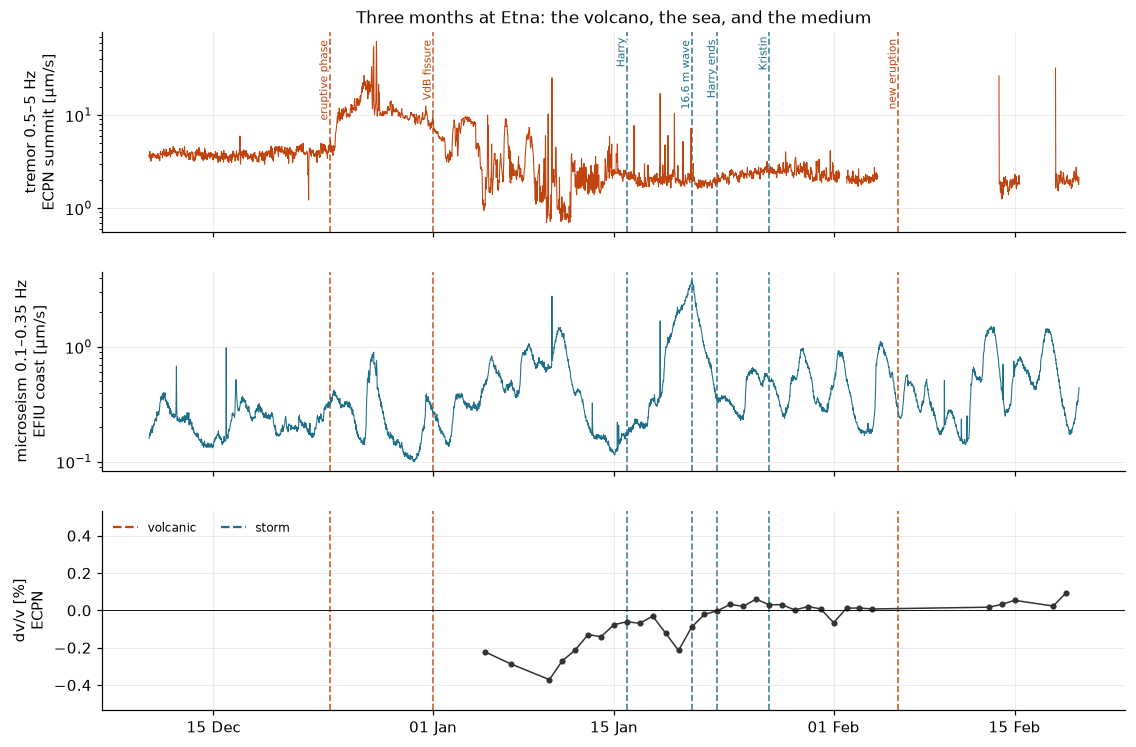

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

t1, v1 = series("ECPN", "tremor")
if t1 is not None:
    # break the line across data gaps, or an outage is drawn as a ramp
    t1, v1 = plots.break_gaps(t1, v1 * 1e6)
    axes[0].semilogy(t1, v1, lw=0.7, color="#c1440e")
axes[0].set_ylabel("tremor 0.5–5 Hz\nECPN summit [µm/s]")

t2, v2 = series("EFIU", "secondary")
if t2 is not None:
    t2, v2 = plots.break_gaps(t2, v2 * 1e6)
    axes[1].semilogy(t2, v2, lw=0.7, color="#1f6f8b")
axes[1].set_ylabel("microseism 0.1–0.35 Hz\nEFIU coast [µm/s]")

g = cc > 0.7
axes[2].plot(dd[g], vv[g], "o-", ms=3, lw=1, color="#333")
axes[2].axhline(0, color="k", lw=0.6)
axes[2].set_ylabel(f"dv/v [%]\n{STA}")
plots.robust_ylim(axes[2], vv, g, symmetric=True)

for ax in axes:
    plots.mark_events(ax, label=(ax is axes[0]), fontsize=7)
plots.date_axis(axes[2])
plots.event_legend(axes[2])
axes[0].set_title("Three months at Etna: the volcano, the sea, and the medium")
plt.show()

## The argument

Work through these in order. Do not skip to the last one.

**1. Which panel responds to which event?**
Go line by line. Does the tremor panel move on the volcanic dates? Does the
microseism panel move on the storm dates? If either one moves on the *wrong*
kind of date, that is interesting and you should say so.

**2. Does dv/v move with either of them?**
Look at the January storm window in particular. If dv/v moves there, you have
three candidate explanations and you need to separate them:

* the *medium* genuinely changed (loading by the atmosphere and the sea,
  pore-pressure change from the rain that came with the storm)
* the *noise source* changed, so the autocorrelation is no longer sampling
  the medium the same way — the storm shifted where the energy comes from,
  not what it travels through
* the measurement simply degraded, and what you see is noise

**3. How would you tell those three apart?**
This is the real question of the session. Some things you could check with
the data you already have:

* does the correlation coefficient drop at the same time? (That points at
  explanation 2 or 3.)
* do all four stations show the same dv/v excursion, or only some? (A real
  medium change should be spatially coherent; a source change should affect
  stations differently depending on their geometry.)
* does dv/v recover when the storm passes, and how fast? (Loading is elastic
  and recovers immediately; damage heals over weeks.)

**4. Now compare across the room.** Each group changed one parameter. Line up
the seven answers.

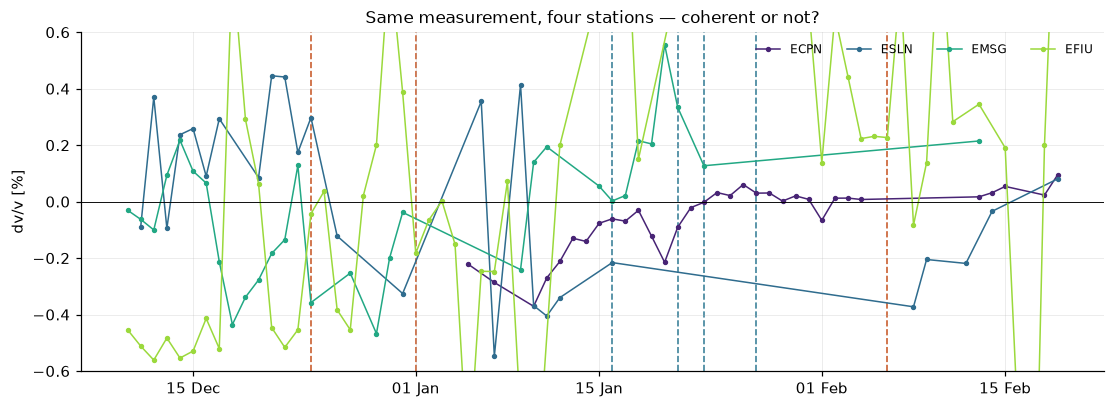

In [4]:
# Check 2 from the list above: is the excursion coherent across stations?
fig, ax = plt.subplots(figsize=(12, 4))
for sta in C.STATIONS:
    k = f"{sta}_acf"
    if k not in Z: continue
    o, _, _ = dvv.dvv_series(Z[k], list(Z[f"{sta}_days"]), lags, (3.0, 15.0),
                             ref_days=None)
    d_ = np.array([np.datetime64(s[0]) for s in o])
    v_ = np.array([s[1] for s in o]); c_ = np.array([s[2] for s in o])
    m = c_ > 0.7
    ax.plot(d_[m], v_[m], "o-", ms=2.5, lw=1, label=sta,
            color=plots.station_color(sta))
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("dv/v [%]")
ax.set_ylim(-0.6, 0.6)
plots.mark_events(ax, label=False); plots.date_axis(ax)
ax.legend(fontsize=8, ncol=4)
ax.set_title("Same measurement, four stations — coherent or not?")
plt.show()

## What you should take away

**Ambient noise is a signal, not a nuisance.** The same continuous record
tells you about the ocean, the weather, human activity and the volcano, and
the only thing that separates them is which frequency band you look in.

**One station is enough to do real work.** H/V and autocorrelation both need
a single sensor. Everything in this practical could be done with one
instrument and a laptop.

**The hard part is never the processing.** Every group in this room ran the
same correct code on the same correct data and got different numbers, because
each of you made a different defensible choice. The measurement is not
"dv/v = x %". The measurement is "dv/v = x %, in this band, in this coda
window, relative to this reference, with this correlation coefficient."
Papers that do not state all five are not reproducible.

**Attribution is a separate problem from detection.** Seeing a change is
easy. Proving *what caused it* needs independent data — meteorological
records, GNSS, gas flux, tilt, thermal imagery. This is why volcano
observatories are multi-parameter, and why your tremor panel and your dv/v
panel sit in different rooms of the same building at INGV-OE in Catania.

---

## Where to go next

* **Multi-station cross-correlation** instead of autocorrelation — gives you
  dispersion curves and, with enough stations, a 3-D velocity model. Etna has
  32 open broadband stations.
* **The `15` microzonation network** — 18 stations in 18 municipalities
  around Etna, open, purpose-built for site response. Notebook 02, scaled up
  to a real hazard map.
* **DAS** — the `4S` dataset is a fibre in a 200 m borehole at Serra La Nave,
  the same site as `ESLN`. Thousands of channels instead of one.
* **Microseism as an ocean sensor** — Cyclone Harry, in your data, is an
  active collaboration between Catania and Bari. Seismometers do not break in
  storms, and they have been running since the 1990s.

Everything above is open data. All of it is reachable with the same four
lines of ObsPy that are in notebook 00.